# ML Assignment 2 — Online Shoppers Purchase Prediction (training notebook)

**Name:** Tanvi Rajesh  
**BITS ID:** 2026AJ05031

This notebook trains the 5 classifiers and produces everything the Streamlit app needs: `model/*.joblib`, `model/metrics.csv`, `model/metrics.md`, `test_data.csv` and a version-pinned `requirements.txt`.

We load the project, look at the data, run `train_models.py`, check the saved models and pack the outputs into `training_outputs.zip`.

## 1. Working from the project folder
We run this on the BITS Virtual Lab Jupyter, from inside the project folder, so the data, the scripts and the `model/` folder are all right here.

In [3]:
import os

# on the BITS Virtual Lab the notebook runs from inside the project folder
PROJECT = os.getcwd()
print("working in:", PROJECT)
print(sorted(os.listdir()))

working in: /home/s2026aj05031/Downloads/online-shoppers-classifier
['.gitignore', '.ipynb_checkpoints', 'ML_Assignment2_2026AJ05031.ipynb', 'README.md', '__pycache__', 'app.py', 'data', 'model', 'requirements.txt', 'shopper_utils.py', 'test_data.csv', 'train_models.py']


## 2. Environment
We print the Python and library versions used for this run. The saved models only load reliably with the same versions, so these are what we pin in `requirements.txt` later, and what Streamlit Cloud has to match.

In [5]:
# versions used for this run
import sys, sklearn, numpy, pandas, joblib, matplotlib, seaborn
print("Python      ", sys.version.split()[0])
for m in (sklearn, numpy, pandas, joblib, matplotlib, seaborn):
    print(f"{m.__name__:12s}", m.__version__)

Python       3.12.7
sklearn      1.6.1
numpy        2.4.6
pandas       2.2.3
joblib       1.6.0
matplotlib   3.10.0
seaborn      0.13.2


## 3. Quick look at the data
We check the size, the duplicate rows, the missing values and how many sessions end in a purchase.

In [7]:
import pandas as pd
df = pd.read_csv("data/online_shoppers_intention.csv")
print("shape:", df.shape, "| duplicates:", df.duplicated().sum(), "| missing values:", df.isnull().sum().sum())
print("\nRevenue split:\n", df["Revenue"].value_counts(normalize=True).round(3))
df.head()

shape: (12330, 18) | duplicates: 125 | missing values: 0

Revenue split:
 Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


What we see: 12,330 rows and 18 columns (17 features + `Revenue`), 125 duplicate rows and no missing values. Only about 15.5% of the sessions end in a purchase, so the classes are imbalanced and accuracy alone would be misleading. That is why we also look at AUC, F1 and MCC.

In [9]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


The count and duration columns are heavily right-skewed. For example `ProductRelated_Duration` has a mean of about 1,195 seconds but a maximum of about 64,000. So in `train_models.py` we apply `log1p` to these columns before scaling them.

## 4. Train all 5 models
`train_models.py` drops the duplicates, makes a stratified 80/20 split and builds the preprocessing. It then trains the five models. Decision Tree, KNN and Naive Bayes are tuned with 5-fold cross-validation on F1. The SVM with probability outputs is the slowest part.

In [12]:
!python train_models.py

dataset: 12205 rows x 17 features
class balance:
 Revenue
False    0.844
True     0.156
Name: proportion, dtype: float64
/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
saved Logistic Regression
Decision Tree best params: {'max_depth': 4, 'min_samples_leaf': 10}
saved Decision Tree
KNN best params: {'n_neighbors': 21, 'weights': 'distance'}
saved KNN
Naive Bayes best params: {'var_smoothing': 1.0}
saved Naive Bayes
saved Support Vector Machine

          ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.8710 0.9255     0.5601  0.8168 0.6645 0.6041
         Decision Tree    0.8480 0.9242     0.5085  0.8586 0.6388 0.5807
                   KNN    0.8964 0.9133     0.7186  0.5550 0.6263 0.5737
           Naive Bayes    0.8562 0.8651     0.5306  0.7042 0.6052 0.5272
Support Vector Machine    0.8595 0.9211     0.5319  0.8508 0.654

## 5. Results
Test-set metrics of every model, side by side.

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8710,0.9255,0.5601,0.8168,0.6645,0.6041
Decision Tree,0.8480,0.9242,0.5085,0.8586,0.6388,0.5807
KNN,0.8964,0.9133,0.7186,0.5550,0.6263,0.5737
Naive Bayes,0.8562,0.8651,0.5306,0.7042,0.6052,0.5272
Support Vector Machine,0.8595,0.9211,0.5319,0.8508,0.6546,0.5971


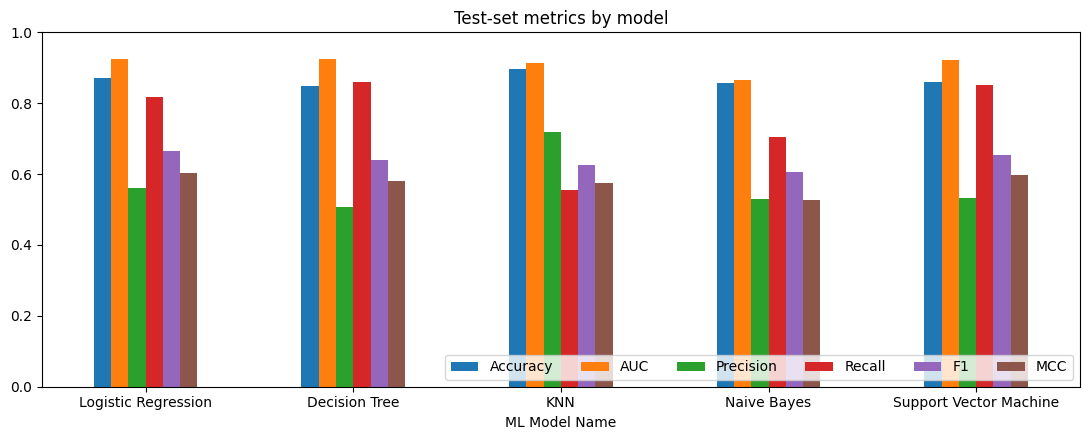

In [14]:
import matplotlib.pyplot as plt
results = pd.read_csv("model/metrics.csv").set_index("ML Model Name")
display(results)
results.plot.bar(figsize=(11, 4.5), rot=0, title="Test-set metrics by model").legend(loc="lower right", ncol=6)
plt.ylim(0, 1); plt.tight_layout(); plt.show()

What we see:
- Logistic Regression has the best AUC, F1 and MCC.
- KNN has the highest accuracy and precision but the lowest recall, so it misses almost half of the real purchases.
- Decision Tree catches the most buyers (highest recall) but has the lowest precision.
- Naive Bayes is the weakest. With the one-hot columns it only reached an accuracy of 0.278, so we trained it on the numeric columns only (see the commit history).
- SVM is very close to Logistic Regression but slower to train.

The same table in markdown form. We copied this into the README.

In [17]:
print(open("model/metrics.md").read())

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.871 | 0.9255 | 0.5601 | 0.8168 | 0.6645 | 0.6041 |
| Decision Tree | 0.848 | 0.9242 | 0.5085 | 0.8586 | 0.6388 | 0.5807 |
| KNN | 0.8964 | 0.9133 | 0.7186 | 0.555 | 0.6263 | 0.5737 |
| Naive Bayes | 0.8562 | 0.8651 | 0.5306 | 0.7042 | 0.6052 | 0.5272 |
| Support Vector Machine | 0.8595 | 0.9211 | 0.5319 | 0.8508 | 0.6546 | 0.5971 |



## 6. Checking the saved models
Here we load each saved `.joblib` model and score `test_data.csv` with it, the same way the app does and without retraining. The numbers match the results table above, so the saved models are fine.

In [19]:
# load every saved model and score the test split, like the app does
import joblib
from shopper_utils import MODEL_FILES, TARGET, clean_features, compute_metrics, to_binary

test = pd.read_csv("test_data.csv")
X_test, y_test = clean_features(test), to_binary(test[TARGET])
check = {}
for name, fname in MODEL_FILES.items():
    model = joblib.load(f"model/{fname}")
    check[name] = compute_metrics(y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1])
pd.DataFrame(check).T.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8710,0.9255,0.5601,0.8168,0.6645,0.6041
Decision Tree,0.8480,0.9242,0.5085,0.8586,0.6388,0.5807
KNN,0.8964,0.9133,0.7186,0.5550,0.6263,0.5737
Naive Bayes,0.8562,0.8651,0.5306,0.7042,0.6052,0.5272
Support Vector Machine,0.8595,0.9211,0.5319,0.8508,0.6546,0.5971


## 7. Pinning the requirements
We write `requirements.txt` with the exact versions from this run, so the saved models load the same way on Streamlit Cloud.

In [21]:
reqs = [f"scikit-learn=={sklearn.__version__}", f"numpy=={numpy.__version__}", f"pandas=={pandas.__version__}",
        f"joblib=={joblib.__version__}", f"matplotlib=={matplotlib.__version__}", f"seaborn=={seaborn.__version__}",
        "streamlit"]
open("requirements.txt", "w").write("\n".join(reqs) + "\n")
print(open("requirements.txt").read())
print("Use Python", sys.version.split()[0][:4], "on Streamlit Cloud")

scikit-learn==1.6.1
numpy==2.4.6
pandas==2.2.3
joblib==1.6.0
matplotlib==3.10.0
seaborn==0.13.2
streamlit

Use Python 3.12 on Streamlit Cloud


## 8. Packaging the outputs
We zip the models, the test data and the requirements into `training_outputs.zip`.

In [23]:
import zipfile

# pack the models, the test split and the requirements into one zip
with zipfile.ZipFile("training_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name in sorted(os.listdir("model")):
        z.write(f"model/{name}")
    z.write("test_data.csv")
    z.write("requirements.txt")
print("saved training_outputs.zip in", PROJECT)

saved training_outputs.zip in /home/s2026aj05031/Downloads/online-shoppers-classifier
